Использую тот же датасет, что в Лабораторной № 1.

In [1]:
import re
from collections import Counter
from tqdm import tqdm

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import spacy
from spacy import displacy

from IPython.display import HTML, display

In [2]:
SUBSET_SIZE = 100_000
SEED = 21

In [3]:
data = pd.read_csv("subset_data.csv", usecols=["comment_text", "label"])

In [4]:
data.head()

,comment_text,label
0,"This is so cool. It's like, 'would you want yo...",0
1,Thank you!! This would make my life a lot less...,0
2,This is such an urgent design problem; kudos t...,0
3,Is this something I'll be able to install on m...,0
4,haha you guys are a bunch of losers.,1


In [5]:
data.shape

(1780822, 2)

In [6]:
data.isna().sum()

comment_text    0
label           0
dtype: int64

In [7]:
data["label"].value_counts().sort_index().to_frame("documents")

,documents
label,
0,1638373
1,142449


Сохраняю принцип получения подвыборки 100 000 документов

In [8]:
subset, _ = train_test_split(
    data,
    train_size=SUBSET_SIZE,
    stratify=data["label"],
    random_state=SEED,
)
subset = subset.copy()

In [9]:
summary = pd.DataFrame({
    "documents": [len(data), len(subset)],
    "toxic_share": [data["label"].mean(), subset["label"].mean()],
}, index=["data", "subset"])

summary

,documents,toxic_share
data,1780822,0.079991
subset,100000,0.079990


# Этап 1. Частеречная разметка (POS-tagging)

Для разметки частей речи и синтаксических зависимостей использую `spaCy`.

Для запуска нужна модель `en_core_web_sm` версии 3.8.0, на которой проверены примеры ошибок разметки.

```
python -m spacy download en_core_web_sm
```


In [10]:
# Отключаю Named Entity Recognition, чтобы ускорить работу пайплайна.
nlp = spacy.load("en_core_web_sm", disable=["ner"])

In [11]:
print("spaCy:", spacy.__version__)
print("Модель:", nlp.meta["name"], nlp.meta["version"])
print("Компоненты:", nlp.pipe_names)

spaCy: 3.8.16
Модель: core_web_sm 3.8.0
Компоненты: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer']


In [12]:
text = subset["comment_text"].iloc[0]
doc = nlp(text)

- `tag` — английская грамматическая метка;
- `morph` — морфологические признаки, зависящие от токена (например число и время);
- `dep` — тип синтаксической связи;
- `head` — токен, от которого зависит текущий. Для корня предложения это сам токен.

In [13]:
print(text)
display(pd.DataFrame([
    {
        "token": token.text,
        "lemma": token.lemma_,
        "pos": token.pos_,
        "tag": token.tag_,
        "morph": str(token.morph),
        "dep": token.dep_,
        "head": token.head.text,
    }
    for token in doc
    if not token.is_space
]))

Big events hinge on small things said Captain Obvious


,token,lemma,pos,tag,morph,dep,head
0,Big,big,ADJ,JJ,Degree=Pos,amod,events
1,events,event,NOUN,NNS,Number=Plur,nsubj,hinge
2,hinge,hinge,VERB,VBP,Tense=Pres|VerbForm=Fin,nsubj,said
3,on,on,ADP,IN,,prep,hinge
4,small,small,ADJ,JJ,Degree=Pos,amod,things
5,things,thing,NOUN,NNS,Number=Plur,pobj,on
6,said,say,VERB,VBD,Tense=Past|VerbForm=Fin,ROOT,said
7,Captain,Captain,PROPN,NNP,Number=Sing,compound,Obvious
8,Obvious,Obvious,PROPN,NNP,Number=Sing,npadvmod,said


# Этап 2. Распределение частей речи и ошибки разметки

POS и синтаксические пары считаем за один проход по подвыборке.

In [14]:
def extract_pairs(doc):
    pairs = []
    for adjective in doc:
        if adjective.pos_ != "ADJ":
            continue

        nouns = []
        if adjective.dep_ == "amod":
            nouns = [adjective.head]
        elif adjective.dep_ == "acomp":
            nouns = [
                child for child in adjective.head.children
                if child.dep_ == "nsubj"
            ]

        for noun in nouns:
            if noun.pos_ in {"NOUN", "PROPN"}:
                pairs.append((noun.lemma_.lower(), adjective.lemma_.lower()))
    return pairs


pos_counts = {0: Counter(), 1: Counter()}
pair_counts = Counter()
pair_examples = {}
pair_counts_by_class = {0: Counter(), 1: Counter()}

In [15]:
documents = zip(subset["comment_text"], subset["label"])
for doc, label in tqdm(
    nlp.pipe(documents, as_tuples=True, batch_size=64),
    total=len(subset),
    desc="Разметка корпуса",
    unit="doc",
    mininterval=5,
):
    pos_counts[label].update(
        token.pos_ for token in doc
        if not token.is_space and not token.is_punct and token.pos_ != "PUNCT"
    )

    for sent in doc.sents:
        for pair in extract_pairs(sent):
            pair_counts[pair] += 1
            pair_counts_by_class[label][pair] += 1
            if pair not in pair_examples:
                pair_examples[pair] = sent.text.strip()

Разметка корпуса: 100%|██████████| 100000/100000 [05:29<00:00, 303.41doc/s]


In [16]:
pos_by_class = pd.DataFrame(pos_counts).fillna(0).astype(int)
pos_by_class = pos_by_class.rename(columns={0: "Нетоксичные", 1: "Токсичные"})
pos_by_class.index.name = "POS"
pos_total = pos_by_class.sum(axis=1).sort_values(ascending=False)

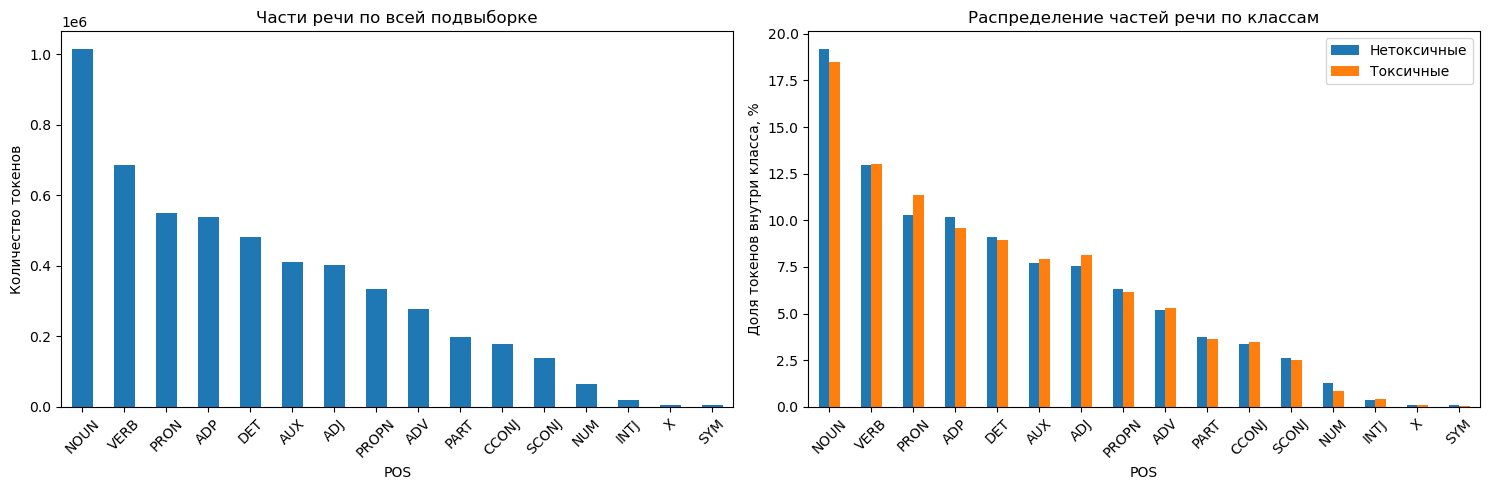

,Нетоксичные,Токсичные
POS,,
NOUN,19.16,18.50
VERB,12.94,13.03
PRON,10.28,11.36
ADP,10.18,9.58
DET,9.08,8.95
AUX,7.70,7.92
ADJ,7.54,8.16
PROPN,6.34,6.13
ADV,5.22,5.29


In [17]:
pos_share = pos_by_class.div(pos_by_class.sum(axis=0), axis=1) * 100
order = pos_total.index

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

pos_total.plot.bar(ax=axes[0], rot=45)
axes[0].set(
    title="Части речи по всей подвыборке",
    xlabel="POS", ylabel="Количество токенов",
)

pos_share.loc[order].plot.bar(ax=axes[1], rot=45)
axes[1].set(
    title="Распределение частей речи по классам",
    xlabel="POS", ylabel="Доля токенов внутри класса, %",
)

plt.tight_layout()
plt.show()

display(pos_share.loc[order].round(2))

В целом части речи распределены примерно одинаково между классами.

В токсичных комментариях выше доля местоимений (11,36% против 10,28%) и прилагательных (8,16% против 7,54%).

In [18]:
patterns = {
    "Сокращения": r"(?i)\b(?:u|ur|r|im|idk|lol|lmao|wtf)\b",
    "Повторы букв": r"(?i)([a-z])\1{2,}",
    "Маскировка слова": r"(?i)\b[a-z]+[*@#$]+[a-z]+\b",
    "Повторы пунктуации": r"[!?]{2,}",
    "Слова в верхнем регистре": r"\b[A-Z]{4,}\b",
}

In [19]:
short_texts = subset.loc[subset["comment_text"].str.len().between(20, 500)]
candidate_parts = []

for noise_type, pattern in patterns.items():
    regex = re.compile(pattern)
    mask = short_texts["comment_text"].map(
        lambda text: regex.search(text) is not None
    )
    matches = short_texts.loc[mask]
    examples = matches.sample(n=min(5, len(matches)), random_state=SEED).copy()
    examples["noise_type"] = noise_type
    candidate_parts.append(examples)

candidates = pd.concat(candidate_parts).drop_duplicates(subset="comment_text")

In [20]:
rows = []

for (row_id, row), doc in zip(
    candidates.iterrows(),
    nlp.pipe(candidates["comment_text"], batch_size=32),
):
    match = re.search(patterns[row["noise_type"]], doc.text)
    span = doc.char_span(match.start(), match.end(), alignment_mode="expand")
    window = doc[max(0, span.start - 2):min(len(doc), span.end + 2)]
    rows.append({
        "id": row_id,
        "noise": row["noise_type"],
        "match": match.group(),
        "context": doc.text[max(0, match.start() - 60):match.end() + 60],
        "POS": " | ".join(
            f"{token.text}/{token.pos_}" for token in window
            if not token.is_space
        ),
    })

candidate_table = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 100, "display.max_rows", 30):
    display(candidate_table)

,id,noise,match,context,POS
0,1535440,Сокращения,U,I strongly urge every pro athletic protesting against the U.S. by disrespecting the flag and Nat...,against/ADP | the/DET | U.S./PROPN | by/ADP | disrespecting/VERB
1,840576,Сокращения,lol,y different from what you think. You have a good day Boots. lol,Boots/NOUN | ./PUNCT | lol/NOUN
2,478076,Сокращения,LOL,"n we have the boy-king babbling his way across the country. LOL, given what he just said about A...","country/NOUN | ./PUNCT | LOL/PROPN | ,/PUNCT | given/VERB"
3,1301728,Сокращения,U,key bit from the Senate hearing on Russian Interference in U.S. Elections\nSenator Richard Burr...,Interference/PROPN | in/ADP | U.S./PROPN | Elections/PROPN
4,1173051,Сокращения,lol,"d solar panels, and maybe end up as prosperous as Ontario.\n\nlol",./PUNCT | lol/NOUN
5,1536117,Повторы букв,kkk,"for black people about what they can and cannot do in Amerikkka. Emily, we were here long befor...",do/VERB | in/ADP | Amerikkka/PROPN | ./PUNCT | Emily/ADV
6,891111,Повторы букв,aaa,"aaa the stupidity of you left wingers never ends,, the usa is a",aaa/VERB | the/DET | stupidity/NOUN
7,193810,Повторы букв,Oooo,"Ooooh, the ""Shoppes at Gateway"" must be much classier than retai","Ooooh/PROPN | ,/PUNCT | the/DET"
8,1254002,Повторы букв,www,sembly. Wag the dog.\n\nMark Knopfler - Working On It\nhttps://www.youtube.com/watch?v=9shw79yxXmY,It/PRON | https://www.youtube.com/watch?v=9shw79yxXmY/PROPN
9,680100,Повторы букв,www,"umbia: The ‘Wild West’ of Canadian Political Cash""\n\nhttps://www.nytimes.com/2017/01/13/world/c...","""/PUNCT | https://www.nytimes.com/2017/01/13/world/canada/british-columbia-christy-clark.html/NO..."


In [21]:
reviewed_ids = [840576, 193810, 1274718, 1459526, 507413]
display(candidate_table.loc[candidate_table["id"].isin(reviewed_ids), [
    "id", "match", "POS",
]])

,id,match,POS
1,840576,lol,Boots/NOUN | ./PUNCT | lol/NOUN
7,193810,Oooo,"Ooooh/PROPN | ,/PUNCT | the/DET"
13,1274718,F***ing,way/NOUN | the/DET | F***ing/PROPN | ball/NOUN...
20,1459526,PETA,dangerous/ADJ | or/CCONJ | PETA/ADJ | throws/V...
24,507413,TOXIC,woman/NOUN | is/AUX | TOXIC/VERB | despite/SCO...


| ID | Фрагмент | Токен | POS модели | Ожидаемая POS | Объяснение |
|---|---|---|---|---|---|
| 840576 | `You have a good day Boots. lol` | `lol` | `NOUN` | `INTJ` | Интернет-сокращение выражает реакцию автора и употреблено отдельно после предложения. Здесь оно не называет предмет и не является существительным. |
| 193810 | `Ooooh, the "Shoppes at Gateway" must be much classier ...` | `Ooooh` | `PROPN` | `INTJ` | Это эмоциональное междометие с растянутым написанием, а не имя собственное. Начальная заглавная буква и нестандартная форма могли затруднить распознавание. |
| 1274718 | `that's the way the F***ing ball bounces` | `F***ing` | `PROPN` | `ADJ` | Замаскированное ругательство употреблено перед `ball` как эмоциональное определение. В данном контексте ожидается прилагательное, а не имя собственное. Это трактовка его функции в предложении, несмотря на глагольное происхождение формы. |
| 1459526 | `it's too dangerous or PETA throws a fit or something` | `PETA` | `ADJ` | `PROPN` | Аббревиатура обозначает организацию, выступающую субъектом действия `throws`. Она является именем собственным, а не прилагательным. |
| 507413 | `This woman is TOXIC despite her age.` | `TOXIC` | `VERB` | `ADJ` | После связки `is` слово описывает свойство человека. Это предикативное прилагательное `toxic`, выделенное верхним регистром, а не глагол. |

# Этап 3. Синтаксический анализ зависимостей (Dependency Parsing)

In [22]:
selected_sentences = []
seen = set()

shuffled = subset.sample(frac=1, random_state=SEED)

for (row_id, row), doc in zip(
    shuffled.iterrows(),
    nlp.pipe(shuffled["comment_text"], batch_size=32),
):
    for sent in doc.sents:
        length = sum(
            not token.is_space and not token.is_punct for token in sent
        )
        text = sent.text.strip()
        if 10 <= length <= 20 and text not in seen:
            seen.add(text)
            selected_sentences.append({
                "id": row_id,
                "label": int(row["label"]),
                "length": length,
                "text": text,
                "span": sent,
            })
        if len(selected_sentences) == 10:
            break
    if len(selected_sentences) == 10:
        break

sentence_table = pd.DataFrame([
    {key: value for key, value in item.items() if key != "span"}
    for item in selected_sentences
])
with pd.option_context("display.max_colwidth", None):
    display(sentence_table)

,id,label,length,text
0,1517958,0,12,Are you okay with heroin being dealt at your local High School?
1,1517958,0,15,But when you compare Heroin deaths with White people and car accidents it's absurd.
2,1550732,0,10,Don't expect anything civil from the NFL overgrown clowns.
3,1550732,0,14,"Hope police continue to shoot everybody who deserves it, just like they always have."
4,139770,0,13,"You're talking, or speculating, about circumstances 5 or 10 years from now."
5,139770,0,15,"Basically, with all due respect, that is not worth very much, except for coffee conversation."
6,458591,0,12,"If you think we are irrelevant, then stop trolling Canadian newspaper sites."
7,262837,0,19,"If you've studied the ethanol fiasco at all, you probably are aware that it's a huge boondoggle."
8,262837,0,11,"The opposition to ethanol should be being expressed in Washington, ""D.C...."
9,1504109,0,18,I would also be concerned if that was top priority in a city with so much heinous crime.


In [23]:
for number, item in enumerate(selected_sentences, start=1):
    print(f"Предложение {number} | ID: {item['id']} | label={item['label']}")
    print(item["text"])
    html = displacy.render(
        item["span"],
        style="dep",
        jupyter=False,
        options={"compact": True, "distance": 100},
    )
    display(HTML(html))

Предложение 1 | ID: 1517958 | label=0
Are you okay with heroin being dealt at your local High School?


Предложение 2 | ID: 1517958 | label=0
But when you compare Heroin deaths with White people and car accidents it's absurd.


Предложение 3 | ID: 1550732 | label=0
Don't expect anything civil from the NFL overgrown clowns.


Предложение 4 | ID: 1550732 | label=0
Hope police continue to shoot everybody who deserves it, just like they always have.


Предложение 5 | ID: 139770 | label=0
You're talking, or speculating, about circumstances 5 or 10 years from now.


Предложение 6 | ID: 139770 | label=0
Basically, with all due respect, that is not worth very much, except for coffee conversation.


Предложение 7 | ID: 458591 | label=0
If you think we are irrelevant, then stop trolling Canadian newspaper sites.


Предложение 8 | ID: 262837 | label=0
If you've studied the ethanol fiasco at all, you probably are aware that it's a huge boondoggle.


Предложение 9 | ID: 262837 | label=0
The opposition to ethanol should be being expressed in Washington, "D.C....


Предложение 10 | ID: 1504109 | label=0
I would also be concerned if that was top priority in a city with so much heinous crime.


- `nsubj` — подлежащее;
- `dobj` — прямое дополнение в разметке этой английской модели;
- `amod` — определение, выраженное прилагательным;
- `attr` и `acomp` — именная и адъективная части сказуемого при соответствующих конструкциях;
- `neg` — отрицание.

Выбрано 10 разных предложений длиной от 10 до 20 токенов без учёта пунктуации и пробелов.

# Этап 4. Извлечение синтаксических пар

Функция извлекает пары «существительное + прилагательное» по связи `amod` и через подлежащее при связи `acomp`.

In [24]:
for item in selected_sentences:
    print(item["text"])
    print(extract_pairs(item["span"]))
    print()

Are you okay with heroin being dealt at your local High School?
[('school', 'local')]

But when you compare Heroin deaths with White people and car accidents it's absurd.
[('people', 'white')]

Don't expect anything civil from the NFL overgrown clowns.
[]

Hope police continue to shoot everybody who deserves it, just like they always have.
[]

You're talking, or speculating, about circumstances 5 or 10 years from now.
[]

Basically, with all due respect, that is not worth very much, except for coffee conversation.
[('respect', 'due')]

If you think we are irrelevant, then stop trolling Canadian newspaper sites.
[('site', 'canadian')]

If you've studied the ethanol fiasco at all, you probably are aware that it's a huge boondoggle.
[('boondoggle', 'huge')]

The opposition to ethanol should be being expressed in Washington, "D.C....
[]

I would also be concerned if that was top priority in a city with so much heinous crime.
[('priority', 'top'), ('crime', 'much'), ('crime', 'heinous')]



# Этап 5. Анализ извлечённых пар

Частоты по классам нормированы на 10 000 извлечённых пар внутри каждого класса.

In [25]:
pair_totals = {label: sum(counts.values()) for label, counts in pair_counts_by_class.items()}
top_pairs = pd.DataFrame([
    {
        "noun": noun,
        "adjective": adjective,
        "count": count,
        "Нетоксичные на 10 000 пар": per_class[0],
        "Токсичные на 10 000 пар": per_class[1],
        "example": pair_examples[(noun, adjective)],
    }
    for (noun, adjective), count in pair_counts.most_common(20)
    for per_class in [[
        round(10_000 * pair_counts_by_class[label][(noun, adjective)] / pair_totals[label], 2)
        for label in (0, 1)
    ]]
])

with pd.option_context("display.max_colwidth", 120):
    display(top_pairs)

,noun,adjective,count,Нетоксичные на 10 000 пар,Токсичные на 10 000 пар,example
0,year,last,864,30.34,21.68,A look at the divorce rates over the last 50 years should give us some insight as to whether the issue is the Church...
1,people,many,665,22.70,24.29,This kind of junk science is why those with an agenda have been able to confuse so many people.
2,news,fake,472,15.81,20.82,"As I posted below, the definition of fake news has been perverted."
3,time,long,449,15.73,11.71,"Indeed, I would argue that you are advancing some sort of passive aggressive and defensive assault in an attempt to ..."
4,class,middle,430,15.28,8.67,"Senseofplace, ""Jr"" is an appropriate description of Trudeau Junior as he is immature, rides off the coat tails of hi..."
5,wing,right,423,13.23,29.49,"The latest Soros accusation, which PolitiFact found to be baseless, shows another aspect of how messages snowball as..."
6,year,next,405,14.43,7.81,"Get used to it Dems, it's your life for the next two years at least."
7,estate,real,389,13.90,6.94,I know several real estate agents who were pleased with the slow summer and are realistic about the 25% gain last ye...
8,money,more,388,13.64,9.54,If they want to withhold votes from the boss then look to the kid on top who made it a priority to give Bombardier m...
9,thing,same,387,13.35,12.58,The bears were doing the same thing.


Частотные пары отражают преимущественно общие выражения и общественно-политическую тематику. 

Например, `last year` указывает время, `federal government` выделяет тему, а `fake news` может выражать оценку. Пара `fake news` встречается 20,82 раза на 10 000 пар в токсичных комментариях и 15,81 раза в нетоксичных. Из одной пары нельзя установить позицию автора: он может цитировать выражение или оспаривать его.

# Этап 6. Разрешение анафоры

Кандидатов ищем в текущем и предыдущем предложениях. Проверяем согласование по числу и, для `he` и `she`, по роду. Затем учитываем предложение, расстояние по дереву зависимостей и расстояние в токенах.

In [26]:
male_words = {"man", "boy", "father", "son", "brother", "husband"}
female_words = {"woman", "girl", "mother", "daughter", "sister", "wife"}
person_words = male_words | female_words | {
    "person", "child", "parent", "friend", "doctor", "teacher", "president",
}

In [27]:
def gender_of(token):
    gender = token.morph.get("Gender")
    if gender:
        return gender[0]
    lemma = token.lemma_.lower()
    if lemma in male_words:
        return "Masc"
    if lemma in female_words:
        return "Fem"
    return None

In [28]:
def tree_distance(a, b):
    # Для разных предложений соединяем корни условной общей вершиной.
    path_a = [a] + list(a.ancestors)
    path_b = [b] + list(b.ancestors)
    positions = {token.i: i for i, token in enumerate(path_a)}
    for j, token in enumerate(path_b):
        if token.i in positions:
            return positions[token.i] + j
    return len(path_a) + len(path_b)

In [29]:
def resolve_pronouns(doc):
    sentences = list(doc.sents)
    sent_number = {
        token.i: number
        for number, sent in enumerate(sentences)
        for token in sent
    }
    sentence_starts = [sent.start for sent in sentences]
    replacements = []

    for pronoun in doc:
        word = pronoun.lower_
        if word not in {"he", "she", "it", "they"}:
            continue
        if pronoun.pos_ != "PRON" or pronoun.dep_ not in {"nsubj", "nsubjpass"}:
            continue

        number = pronoun.morph.get("Number")
        if not number:
            continue
        sentence = sent_number[pronoun.i]
        start = sentence_starts[max(0, sentence - 1)]
        candidates = []
        for noun in doc[start:pronoun.i]:
            if noun.pos_ not in {"NOUN", "PROPN"}:
                continue
            if noun.morph.get("Number") != number:
                continue
            if word in {"he", "she"}:
                expected = gender_of(pronoun) or ("Masc" if word == "he" else "Fem")
                if gender_of(noun) != expected:
                    continue
            if word == "it" and (
                noun.pos_ == "PROPN"
                or noun.lemma_.lower() in person_words
                or gender_of(noun) in {"Masc", "Fem"}
            ):
                continue
            candidates.append(noun)

        if not candidates:
            continue
        best = min(candidates, key=lambda noun: (
            sent_number[pronoun.i] - sent_number[noun.i],
            tree_distance(noun, pronoun),
            pronoun.i - noun.i,
        ))
        replacements.append((pronoun, best))

    changed = doc.text
    for pronoun, noun in reversed(replacements):
        replacement = noun.text
        if pronoun.i == pronoun.sent.start:
            replacement = replacement[:1].upper() + replacement[1:]
        start = pronoun.idx
        changed = changed[:start] + replacement + changed[start + len(pronoun.text):]
    return changed, replacements

In [30]:
examples = []
check_data = subset.sample(n=min(2000, len(subset)), random_state=SEED)

In [31]:
for (row_id, row), doc in zip(
    check_data.iterrows(),
    nlp.pipe(check_data["comment_text"], batch_size=32),
):
    changed, replacements = resolve_pronouns(doc)
    if replacements:
        examples.append({
            "id": row_id,
            "original": doc.text,
            "changed": changed,
            "replacements": "; ".join(
                f"{pronoun.text} → {noun.text}"
                for pronoun, noun in replacements
            ),
        })
    if len(examples) == 10:
        break

anaphora_examples = pd.DataFrame(examples)
with pd.option_context("display.max_colwidth", 180):
    display(anaphora_examples)

,id,original,changed,replacements
0,1517958,No I am not. Are you okay with heroin being dealt at your local High School? Ghetto? Neighborhood? City? Anywhere? But when you compare Heroin deaths with White people and ...,No I am not. Are you okay with heroin being dealt at your local High School? Ghetto? Neighborhood? City? Anywhere? But when you compare Heroin deaths with White people and ...,it → car
1,1550732,"Don't care what the ""protests"" are about. Don't care what you think. Don't expect anything civil from the NFL overgrown clowns. \n\nHope police continue to shoot everybody who...","Don't care what the ""protests"" are about. Don't care what you think. Don't expect anything civil from the NFL overgrown clowns. \n\nHope police continue to shoot everybody who...",they → police
2,1063374,"Let's acknowledge that more than a thousand years before European voyagers crossed the Atlantic Ocean, Polynesians were sailing across the much larger Pacific Ocean. What made...","Let's acknowledge that more than a thousand years before European voyagers crossed the Atlantic Ocean, Polynesians were sailing across the much larger Pacific Ocean. What made...",they → Europeans; they → Polynesians
3,262837,Motley: In fact the conversion of millions of acres of commodity grains (including feed corn) to subsidized ethanol corn has tremendously impacted the grain market and the pri...,Motley: In fact the conversion of millions of acres of commodity grains (including feed corn) to subsidized ethanol corn has tremendously impacted the grain market and the pri...,it → fiasco
4,1504109,"Of course. I would also be concerned if that was top priority in a city with so much heinous crime. \n\nSee, to me, I would call this good aim and good riddance. But the law d...","Of course. I would also be concerned if that was top priority in a city with so much heinous crime. \n\nSee, to me, I would call this good aim and good riddance. But the law d...",it → guy
5,748856,"Yes! On the one hand, their ignorance about teenage girls and different socioeconomic classes was incredible. I had a great opportunity. My folks moved me from a working cla...","Yes! On the one hand, their ignorance about teenage girls and different socioeconomic classes was incredible. I had a great opportunity. My folks moved me from a working cla...",They → stands
6,751184,"Yep ! Trump Jr is Right! This is how they combat Terrorism in London; when a tragedy happens; They light candles, hold vigils, holding hands singing Kumbaya,""Making Shapes of...","Yep ! Trump Jr is Right! This is how they combat Terrorism in London; when a tragedy happens; They light candles, hold vigils, holding hands singing Kumbaya,""Making Shapes of...",It → mentality
7,1051153,"Well, many people legally can't vote so they are out. I didn't live here then so I am out. I don't even know how well publicized the vote was. Maybe now, people are paying mor...","Well, many people legally can't vote so people are out. I didn't live here then so I am out. I don't even know how well publicized the vote was. Maybe now, people are paying m...",they → people; it → turn; it → monkey
8,1667213,"When the Repubicks refused to do jack___\nafter 20 six year olds were blown away,\ndon""t expect anything, from the next mass shooting.\nThey could give a flyin""____, 10 dozen ,...","When the Repubicks refused to do jack___\nafter 20 six year olds were blown away,\ndon""t expect anything, from the next mass shooting.\nOlds could give a flyin""____, 10 dozen ,...",They → olds; they → olds
9,484732,Who in their right mind would ignore the poor optics of this?\nRabid partisans.\nAll the PM had to do was pay for the chopper ride and a nominal fee for accommodation to avoid ...,Who in their right mind would ignore the poor optics of this?\nRabid partisans.\nAll the PM had to do was pay for the chopper ride and a nominal fee for accommodation to avoid ...,it → scandal


In [32]:
reviewed_anaphora_ids = [1550732, 1063374, 1106527, 99668, 1117493, 1584252]

for row_id in reviewed_anaphora_ids:
    text = subset.loc[row_id, "comment_text"]
    changed, replacements = resolve_pronouns(nlp(text))
    print(f"ID: {row_id}")
    print("Исходный текст:", text)
    print("После замены:", changed)
    print("Связи:", [(p.text, n.text) for p, n in replacements])
    print()

ID: 1550732
Исходный текст: Don't care what the "protests" are about.  Don't care what you think. Don't expect anything civil from the NFL overgrown clowns. 

Hope police continue to shoot everybody who deserves it, just like they always have.
После замены: Don't care what the "protests" are about.  Don't care what you think. Don't expect anything civil from the NFL overgrown clowns. 

Hope police continue to shoot everybody who deserves it, just like police always have.
Связи: [('they', 'police')]

ID: 1063374
Исходный текст: Let's acknowledge that more than a thousand years before European voyagers crossed the Atlantic Ocean, Polynesians were sailing across the much larger Pacific Ocean.  What made the difference?  While the Europeans viewed themselves as separate from nature--and believing they had to conquer the seas, Polynesians knew they were one with the nature, including the ocean.  Hence, while Europeans relied on technology to sail beyond the sight of land, the Polynesians re

| ID | Исходный фрагмент | После замены | Оценка и объяснение |
|---|---|---|---|
| 1550732 | `Hope police continue to shoot everybody who deserves it, just like they always have.` | `Hope police continue to shoot everybody who deserves it, just like police always have.` | Правильно: `they` относится к `police`; число согласовано. Объектное `it` алгоритм не меняет, поскольку рассматривает только подлежащие. |
| 1063374 | `Polynesians knew they were one with the nature` | `Polynesians knew Polynesians were one with the nature` | Правильно: `they` относится к `Polynesians`. Повтор делает фразу тяжелее, но референт выбран верно. |
| 1106527 | `Any posting using such words on a Globe & Mail forum would be deleted, that is, if it ever passed the filters.` | `Any posting using such words on a Globe & Mail forum would be deleted, that is, if posting ever passed the filters.` | Антецедент выбран правильно: речь о публикации `posting`. Однако для естественной английской фразы при подстановке нужен определитель: например, `the posting`. |
| 99668 | `people are denied the most desirable bartending/hospitality jobs because they are NOT gay` | `people are denied the most desirable bartending/hospitality jobs because jobs are NOT gay` | Ошибка: `they` относится к людям (`people`), а не к рабочим местам (`jobs`). Совпадения числа и структурной близости недостаточно без семантики. |
| 1117493 | `It seems to me that some bloggers are always looking at other people's lives` | `Unity seems to me that some bloggers are always looking at other people's lives` | Ошибка: здесь `It` — формальное подлежащее конструкции `It seems ... that ...`, не отсылка к существительному `Unity` из предыдущего предложения. |
| 1584252 | `... signed an $858 billion tax cut deal. It extended the Bush tax cuts ...` | `... signed an $858 billion tax cut deal. Deal extended the Bush tax cuts ...` | Антецедент `deal` выбран правильно, но для естественности требуется `The deal`. |
| 1584252 | `It cut payroll taxes by 2 percent` | `Unemployment cut payroll taxes by 2 percent` | Ошибка следующей замены в том же документе: `It` всё ещё относится к соглашению `deal`, но алгоритм выбрал `unemployment` из предыдущего предложения. Он не поддерживает цепочки кореференции. |

Правила позволяют находить некоторые локальные связи, когда местоимение и существительное согласованы по числу и расположены близко в синтаксической структуре.

Тем не менее, есть и ошибки (например, местоимение, относящееся к людям, заменено на `jobs`).

Отдельная проблема — формальное подлежащее `it`, которое не имеет антецедента-существительного.